<a href="https://colab.research.google.com/github/saisathvik485/BIS-LAB-5M-/blob/main/image_edge_detection_using_ant_colony_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[System] Created a dummy test image at 'input.jpg' because none was found.
Extracted 350 edge nodes. Running ACO...
Optimization complete. Shortest path length: 1644.61


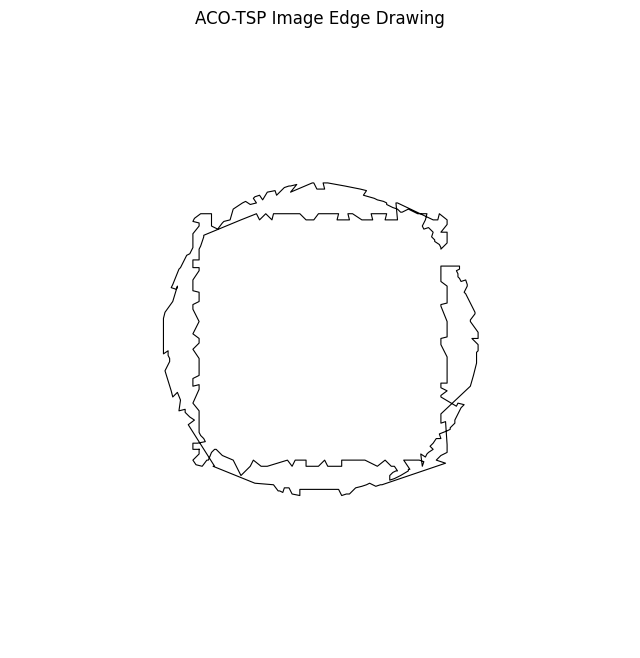

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import os


def create_dummy_image(image_path):
    """Generates a dummy image with a circle and rectangle if input.jpg is missing."""
    # Create a 400x400 white canvas
    img = np.ones((400, 400), dtype=np.uint8) * 255
    # Draw a black circle
    cv2.circle(img, (200, 200), 100, (0, 0, 0), 2)
    # Draw a black rectangle
    cv2.rectangle(img, (120, 120), (280, 280), (0, 0, 0), 2)
    cv2.imwrite(image_path, img)
    print(f"[System] Created a dummy test image at '{image_path}' because none was found.")


def extract_edge_nodes(image_path, max_nodes=300):
    """Detects edges in an image and samples (x, y) coordinates as TSP cities."""
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not load image at {image_path}")

    # Apply Gaussian blur and Canny edge detection
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    edges = cv2.Canny(blurred, threshold1=50, threshold2=150)

    # Extract (x, y) coordinates of edge pixels
    y_indices, x_indices = np.where(edges > 0)
    coords = np.column_stack((x_indices, y_indices))

    # Downsample if edge pixels exceed max_nodes
    if len(coords) > max_nodes:
        idx = np.random.choice(len(coords), size=max_nodes, replace=False)
        coords = coords[idx]

    return coords, img.shape


def aco_tsp(
    cities, num_ants=25, max_iter=100, alpha=1.0, beta=4.0, rho=0.5, q=100.0
):
    """Finds the shortest closed path visiting all extracted edge coordinates."""
    n = len(cities)

    # Precompute Euclidean distance and heuristic matrices
    diff = cities[:, np.newaxis, :] - cities[np.newaxis, :, :]
    dist = np.sqrt(np.sum(diff**2, axis=-1)) + 1e-10
    heuristic = (1.0 / dist) ** beta
    pheromone = np.ones((n, n)) * 0.1

    best_tour = None
    best_length = float("inf")

    for _ in range(max_iter):
        all_tours = []
        all_lengths = []

        for _ in range(num_ants):
            start = np.random.randint(0, n)
            tour = [start]
            visited = np.zeros(n, dtype=bool)
            visited[start] = True
            curr = start

            for _ in range(n - 1):
                unvisited = np.where(~visited)[0]
                probs = (pheromone[curr, unvisited] ** alpha) * heuristic[
                    curr, unvisited
                ]
                probs /= np.sum(probs)

                next_city = np.random.choice(unvisited, p=probs)
                tour.append(next_city)
                visited[next_city] = True
                curr = next_city

            # Calculate closed tour distance
            tour_arr = np.array(tour)
            length = np.sum(dist[tour_arr, np.roll(tour_arr, -1)])

            all_tours.append(tour_arr)
            all_lengths.append(length)

            if length < best_length:
                best_length = length
                best_tour = tour_arr

        # Evaporate and deposit pheromones
        pheromone *= 1.0 - rho
        for tour_arr, length in zip(all_tours, all_lengths):
            deposit = q / length
            nxt = np.roll(tour_arr, -1)
            pheromone[tour_arr, nxt] += deposit
            pheromone[nxt, tour_arr] += deposit

    return best_tour, best_length


def plot_tsp_art(cities, best_tour, img_shape):
    """Draws the continuous TSP line art."""
    ordered_cities = cities[np.append(best_tour, best_tour[0])]

    plt.figure(figsize=(8, 8))
    plt.plot(
        ordered_cities[:, 0], ordered_cities[:, 1], color="black", linewidth=0.8
    )
    plt.xlim(0, img_shape[1])
    plt.ylim(img_shape[0], 0)  # Invert Y-axis to match image coordinates
    plt.axis("off")
    plt.title("ACO-TSP Image Edge Drawing")
    plt.show()


if __name__ == "__main__":
    IMAGE_PATH = "input.jpg"  # Replace with your image path

    # Generate a dummy image if the user hasn't uploaded one
    if not os.path.exists(IMAGE_PATH):
        create_dummy_image(IMAGE_PATH)

    cities, shape = extract_edge_nodes(IMAGE_PATH, max_nodes=350)
    print(f"Extracted {len(cities)} edge nodes. Running ACO...")

    best_tour, best_length = aco_tsp(cities, num_ants=25, max_iter=100)
    print(f"Optimization complete. Shortest path length: {best_length:.2f}")

    plot_tsp_art(cities, best_tour, shape)